# Calibrazione del campo e zone P1-P6

Notebook separato dal fine-tuning YOLO: seleziona un video e un istante, calibra i quattro angoli del campo e crea l'overlay e la maschera delle 12 zone. Il campo e modellato come rettangolo 9 x 18 m; la calibrazione del pavimento continua a usare un'omografia indipendente dalla stima della camera 3D.

La mappa delle zone e una convenzione geometrica, non deduce ruoli o competenze tattiche. L'estensione avversaria resta configurabile in metri. La sola omografia non fornisce la posizione 3D di tribune, persone o pallone in aria.

Per la camera 3D il notebook raccoglie i quattro angoli a terra, sei punti sul nastro superiore/inferiore della rete e, se visibili, due punte alte delle antenne. Il fit stima fx, fy e centro ottico, assumendo skew zero e distorsione trascurabile; non e una calibrazione metrologica. Sag, altezze nominali e click imprecisi possono far rifiutare il fit senza invalidare omografia o zone. I JSON schema 1 e 2 restano caricabili; le nuove calibrazioni sono schema 3.


In [9]:
from pathlib import Path
import json
import cv2
import numpy as np
from IPython.display import display

WORKSPACE_DIR = Path.cwd().resolve()
VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv", ".m4v"}
EXCLUDED_DIRS = {"runs", ".git", ".venv", "venv", "__pycache__"}
VIDEO_FILES = sorted(
    path.resolve()
    for path in WORKSPACE_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in VIDEO_EXTENSIONS
    and not any(part in EXCLUDED_DIRS or part.startswith(".venv-") for part in path.relative_to(WORKSPACE_DIR).parts)
)
if not VIDEO_FILES:
    raise FileNotFoundError(f"Nessun video trovato sotto {WORKSPACE_DIR}")
print(f"Cartella di lavoro: {WORKSPACE_DIR}")
for i, path in enumerate(VIDEO_FILES, start=1):
    print(f"{i}. {path.relative_to(WORKSPACE_DIR)}")

Cartella di lavoro: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP
1. Annotazioni\ITA_POL_VNL2024_30fps.mp4
2. Annotazioni\ITA_SRB_Parigi2024_30fps.mp4
3. Annotazioni\Test_demo_ITA_DOM_Parigi2024_30fps.mp4


## Video e frame di calibrazione

Scegli un video dall'elenco e il timestamp in secondi. Il frame viene mostrato in RGB. Per una camera fissa scegli un fotogramma nitido in cui siano visibili le quattro intersezioni delle linee esterne del campo.

Se il kernel non ha i widget, non aggiungere dipendenze al kernel del training in corso. Puoi creare un kernel isolato (PowerShell, dalla cartella di lavoro):

```powershell
py -3.14 -m venv .venv-zone
.\.venv-zone\Scripts\python.exe -m pip install --upgrade pip
.\.venv-zone\Scripts\python.exe -m pip install opencv-python numpy matplotlib ipywidgets ipyevents ipykernel
.\.venv-zone\Scripts\python.exe -m ipykernel install --user --name scout-zone --display-name "Python (Scout zone)"
```

Se il comando `py -3.14` non è disponibile, usa il percorso dell'interprete Python installato al posto di `py -3.14`.

In [10]:
import importlib.util

missing_widgets = [name for name in ("ipywidgets", "ipyevents") if importlib.util.find_spec(name) is None]
if missing_widgets:
    raise ModuleNotFoundError(
        "Per i click interattivi servono ipywidgets e ipyevents nel kernel di questo notebook. "
        "Non installarli nel kernel del training in esecuzione: crea un ambiente Jupyter separato, "
        "installa lì opencv-python, numpy, matplotlib, ipywidgets, ipyevents e ipykernel, "
        "registralo come kernel e riavvia questo notebook."
    )
import ipywidgets as widgets
from ipyevents import Event

video_dropdown = widgets.Dropdown(
    options=[(str(p.relative_to(WORKSPACE_DIR)), str(p)) for p in VIDEO_FILES],
    description="Video:",
    layout=widgets.Layout(width="min(100%, 900px)"),
)
timestamp_input = widgets.FloatText(value=10.0, description="Secondi:", step=1.0)
load_frame_button = widgets.Button(description="Carica frame", button_style="primary")
frame_output = widgets.Output()
display(widgets.HBox([timestamp_input, load_frame_button]), video_dropdown, frame_output)

VIDEO_PATH = None
FRAME_SECONDS = None
FRAME_BGR = None
FRAME_RGB = None
FRAME_WIDTH = None
FRAME_HEIGHT = None

def load_selected_frame(_=None):
    global VIDEO_PATH, FRAME_SECONDS, FRAME_BGR, FRAME_RGB, FRAME_WIDTH, FRAME_HEIGHT
    seconds = float(timestamp_input.value)
    if seconds < 0:
        raise ValueError("Il timestamp deve essere non negativo.")
    path = Path(video_dropdown.value)
    cap = cv2.VideoCapture(str(path))
    try:
        if not cap.isOpened():
            raise OSError(f"Impossibile aprire il video: {path}")
        duration = cap.get(cv2.CAP_PROP_FRAME_COUNT) / max(cap.get(cv2.CAP_PROP_FPS), 1e-9)
        if seconds > duration:
            raise ValueError(f"Timestamp {seconds:g}s oltre la durata ({duration:.1f}s).")
        cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
        ok, bgr = cap.read()
        if not ok:
            raise RuntimeError(f"Frame non leggibile al timestamp {seconds:g}s.")
    finally:
        cap.release()
    VIDEO_PATH = path.resolve()
    FRAME_SECONDS = seconds
    FRAME_BGR = bgr
    FRAME_RGB = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    FRAME_HEIGHT, FRAME_WIDTH = FRAME_BGR.shape[:2]
    with frame_output:
        frame_output.clear_output(wait=True)
        print(f"{VIDEO_PATH.name} — {seconds:g}s — {FRAME_WIDTH}×{FRAME_HEIGHT} px")
        import matplotlib.pyplot as plt
        plt.figure(figsize=(12, 6.75))
        plt.imshow(FRAME_RGB)
        plt.axis("off")
        plt.show()

load_frame_button.on_click(load_selected_frame)

Dropdown(description='Video:', layout=Layout(width='min(100%, 900px)'), options=(('Annotazioni\\ITA_POL_VNL202…

Output()

## Selezione interattiva dei quattro angoli

Fai click **nell'ordine indicato**: `alto-sinistra` (fondo lontano), `alto-destra`, `basso-destra`, `basso-sinistra` (fondo vicino). Seleziona le intersezioni del rettangolo esterno del terreno, non i pali o le linee della rete. Usa **Reset** per ripartire; **Conferma angoli** controlla punti, ordine, convessita e area. Poi esegui la cella successiva per selezionare il bordo superiore della rete.


In [11]:
CORNER_NAMES = ["alto-sinistra / fondo lontano", "alto-destra / fondo lontano", "basso-destra / fondo vicino", "basso-sinistra / fondo vicino"]
CONFIRMED_CORNERS = None

def validate_corners(points, width, height):
    pts = np.asarray(points, dtype=np.float64)
    if pts.shape != (4, 2) or not np.isfinite(pts).all():
        raise ValueError("Servono quattro punti finiti, nell'ordine richiesto.")
    if np.any(pts[:, 0] < 0) or np.any(pts[:, 0] >= width) or np.any(pts[:, 1] < 0) or np.any(pts[:, 1] >= height):
        raise ValueError("Uno o più punti sono fuori dal frame.")
    edges = np.roll(pts, -1, axis=0) - pts
    next_edges = np.roll(edges, -1, axis=0)
    turns = edges[:, 0] * next_edges[:, 1] - edges[:, 1] * next_edges[:, 0]
    if np.any(turns <= 1e-6):
        raise ValueError("I punti non formano un quadrilatero convesso nell'ordine alto-sinistra, alto-destra, basso-destra, basso-sinistra.")
    area = 0.5 * abs(np.dot(pts[:, 0], np.roll(pts[:, 1], -1)) - np.dot(pts[:, 1], np.roll(pts[:, 0], -1)))
    if area < width * height * 0.01:
        raise ValueError("Quadrilatero troppo piccolo rispetto al frame: ricontrolla i click.")
    return pts

if FRAME_RGB is None:
    raise RuntimeError("Prima carica un video e un frame nella cella precedente.")

from PIL import Image, ImageDraw
import io

DISPLAY_WIDTH = min(FRAME_WIDTH, 960)
DISPLAY_HEIGHT = round(FRAME_HEIGHT * DISPLAY_WIDTH / FRAME_WIDTH)
selected_points = []
selection_status = widgets.HTML(value="<b>0/4</b> punti selezionati")
frame_widget = widgets.Image(format="png", layout=widgets.Layout(width=f"{DISPLAY_WIDTH}px", height=f"{DISPLAY_HEIGHT}px"))
reset_button = widgets.Button(description="Reset")
confirm_button = widgets.Button(description="Conferma angoli", button_style="success")
selection_output = widgets.Output()

def render_selection():
    image = Image.fromarray(FRAME_RGB).resize((DISPLAY_WIDTH, DISPLAY_HEIGHT))
    draw = ImageDraw.Draw(image)
    for index, (x, y) in enumerate(selected_points):
        dx, dy = x * DISPLAY_WIDTH / FRAME_WIDTH, y * DISPLAY_HEIGHT / FRAME_HEIGHT
        r = 8
        draw.ellipse((dx-r, dy-r, dx+r, dy+r), fill="yellow", outline="black", width=2)
        draw.text((dx+10, dy+4), str(index+1), fill="yellow", stroke_width=2, stroke_fill="black")
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    frame_widget.value = buffer.getvalue()
    if len(selected_points) < 4:
        selection_status.value = f"<b>{len(selected_points)}/4</b> — click: {CORNER_NAMES[len(selected_points)]}"
    else:
        selection_status.value = "<b>4/4</b> — premi Conferma angoli oppure Reset"

def handle_frame_click(event):
    if CONFIRMED_CORNERS is not None or len(selected_points) >= 4:
        return
    x = float(event["relativeX"]) * FRAME_WIDTH / DISPLAY_WIDTH
    y = float(event["relativeY"]) * FRAME_HEIGHT / DISPLAY_HEIGHT
    selected_points.append((x, y))
    render_selection()

def reset_selection(_):
    global CONFIRMED_CORNERS
    CONFIRMED_CORNERS = None
    selected_points.clear()
    with selection_output:
        selection_output.clear_output(wait=True)
    render_selection()

def confirm_selection(_):
    global CONFIRMED_CORNERS
    with selection_output:
        selection_output.clear_output(wait=True)
        try:
            CONFIRMED_CORNERS = validate_corners(selected_points, FRAME_WIDTH, FRAME_HEIGHT)
            print("Angoli confermati (pixel):")
            for name, point in zip(CORNER_NAMES, CONFIRMED_CORNERS):
                print(f"  {name}: ({point[0]:.1f}, {point[1]:.1f})")
        except ValueError as exc:
            CONFIRMED_CORNERS = None
            print(f"Selezione non valida: {exc}")

click_events = Event(source=frame_widget, watched_events=["click"])
click_events.on_dom_event(handle_frame_click)
reset_button.on_click(reset_selection)
confirm_button.on_click(confirm_selection)
render_selection()
display(selection_status, frame_widget, widgets.HBox([reset_button, confirm_button]), selection_output)

HTML(value='<b>0/4</b> — click: alto-sinistra / fondo lontano')

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x03\xc0\x00\x00\x02\x1c\x08\x02\x00\x00\x00\xb6?P,\x…

Output()

## Selezione dei punti 3D noti sulla rete

Dopo i quattro angoli a terra, annota in ordine immagine sinistra-centro-destra: i tre punti del bordo superiore, poi i tre del bordo inferiore. Le coordinate mondo seguono i corner gia confermati: lato sinistro x=0 m, centro x=4.5 m, lato destro x=9 m; tutti hanno y=9 m. Il bordo superiore e nominalmente z=2.24 m (altezza regolamentare femminile al centro), il bordo inferiore circa z=1.24 m assumendo una fascia larga 1 m.

Se visibili, annota anche le due punte superiori delle antenne (opzionali), nominalmente a z=3.04 m (2.24 + 0.80 m). Usa "Salta punto opzionale" per saltare soltanto una punta non visibile. I sei punti sul nastro sono obbligatori. Controlla l'overlay con codici e coordinate e premi Conferma punti 3D; solo dopo, la cella di salvataggio scrivera il JSON.

Le quote sono un modello rigido nominale: gli estremi superiori possono essere fino a circa 2 cm piu alti della quota centrale e la rete puo cedere. I residui rete possono quindi segnalare sag o quote nominali non rispettate; non indicano automaticamente un click errato. L'omografia del pavimento resta valida anche se la stima camera e rifiutata.


In [12]:
COURT_NET_HEIGHT_M = 2.24  # rete femminile; quota regolamentare misurata al centro.
NET_BAND_HEIGHT_M = 1.0
NET_BOTTOM_HEIGHT_M = COURT_NET_HEIGHT_M - NET_BAND_HEIGHT_M
ANTENNA_EXTENSION_M = 0.80
ANTENNA_TIP_HEIGHT_M = COURT_NET_HEIGHT_M + ANTENNA_EXTENSION_M
CONFIRMED_NET_CORRESPONDENCES = None
CONFIRMED_NET_SEGMENT = None  # compatibilita: estremi del nastro superiore x=0 -> x=9.
CONFIRMED_SKIPPED_OPTIONAL_POINTS = []

NET_POINT_SPECS = [
    {"code": "TOP-L", "name": "nastro superiore - sinistra", "world_xyz_m": [0.0, 9.0, COURT_NET_HEIGHT_M], "required": True, "z_tolerance_m": 0.02},
    {"code": "TOP-C", "name": "nastro superiore - centro esatto", "world_xyz_m": [4.5, 9.0, COURT_NET_HEIGHT_M], "required": True, "z_tolerance_m": 0.0},
    {"code": "TOP-R", "name": "nastro superiore - destra", "world_xyz_m": [9.0, 9.0, COURT_NET_HEIGHT_M], "required": True, "z_tolerance_m": 0.02},
    {"code": "BOT-L", "name": "nastro inferiore - sinistra", "world_xyz_m": [0.0, 9.0, NET_BOTTOM_HEIGHT_M], "required": True, "z_tolerance_m": 0.02},
    {"code": "BOT-C", "name": "nastro inferiore - centro esatto", "world_xyz_m": [4.5, 9.0, NET_BOTTOM_HEIGHT_M], "required": True, "z_tolerance_m": 0.0},
    {"code": "BOT-R", "name": "nastro inferiore - destra", "world_xyz_m": [9.0, 9.0, NET_BOTTOM_HEIGHT_M], "required": True, "z_tolerance_m": 0.02},
    {"code": "ANT-L", "name": "punta alta antenna - sinistra (opzionale)", "world_xyz_m": [0.0, 9.0, ANTENNA_TIP_HEIGHT_M], "required": False, "z_tolerance_m": 0.02},
    {"code": "ANT-R", "name": "punta alta antenna - destra (opzionale)", "world_xyz_m": [9.0, 9.0, ANTENNA_TIP_HEIGHT_M], "required": False, "z_tolerance_m": 0.02},
]
if FRAME_RGB is None or CONFIRMED_CORNERS is None:
    raise RuntimeError("Carica un frame e conferma i quattro angoli: determinano il verso x=0 -> x=9.")
from PIL import Image, ImageDraw
import io
DISPLAY_WIDTH = min(FRAME_WIDTH, 960)
DISPLAY_HEIGHT = round(FRAME_HEIGHT * DISPLAY_WIDTH / FRAME_WIDTH)
net_selected_images, net_skipped_codes, net_selection_history = {}, set(), []
net_selection_cursor = 0
net_selection_status = widgets.HTML()
net_frame_widget = widgets.Image(format="png", layout=widgets.Layout(width=f"{DISPLAY_WIDTH}px", height=f"{DISPLAY_HEIGHT}px"))
net_reset_button = widgets.Button(description="Reset")
net_undo_button = widgets.Button(description="Annulla ultimo")
net_skip_button = widgets.Button(description="Salta punto opzionale")
net_confirm_button = widgets.Button(description="Conferma punti 3D", button_style="success")
net_selection_output = widgets.Output()

def render_net_selection():
    image = Image.fromarray(FRAME_RGB).resize((DISPLAY_WIDTH, DISPLAY_HEIGHT))
    draw = ImageDraw.Draw(image)
    for spec in NET_POINT_SPECS:
        if spec["code"] not in net_selected_images:
            continue
        x, y = net_selected_images[spec["code"]]
        dx, dy = x * DISPLAY_WIDTH / FRAME_WIDTH, y * DISPLAY_HEIGHT / FRAME_HEIGHT
        draw.ellipse((dx-8, dy-8, dx+8, dy+8), fill="cyan", outline="black", width=2)
        draw.text((dx+10, dy+3), spec["code"], fill="cyan", stroke_width=2, stroke_fill="black")
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    net_frame_widget.value = buffer.getvalue()
    if net_selection_cursor < len(NET_POINT_SPECS):
        spec = NET_POINT_SPECS[net_selection_cursor]
        net_selection_status.value = (f"<b>{len(net_selected_images)}/6 obbligatori</b>; antenne saltate {len(net_skipped_codes)}/2<br>"
            f"Click <b>{spec['code']}</b> {spec['name']}; mondo {spec['world_xyz_m']} m")
        net_skip_button.disabled = bool(spec["required"])
    else:
        net_selection_status.value = f"<b>Selezione completa</b>: {len(net_selected_images)} punti acquisiti, {len(net_skipped_codes)} antenne saltate. Controlla e conferma."
        net_skip_button.disabled = True

def handle_net_click(event):
    global net_selection_cursor
    if CONFIRMED_NET_CORRESPONDENCES is not None or net_selection_cursor >= len(NET_POINT_SPECS):
        return
    spec = NET_POINT_SPECS[net_selection_cursor]
    xy = (float(event["relativeX"]) * FRAME_WIDTH / DISPLAY_WIDTH,
          float(event["relativeY"]) * FRAME_HEIGHT / DISPLAY_HEIGHT)
    net_selected_images[spec["code"]] = xy
    net_selection_history.append(("point", spec["code"]))
    net_selection_cursor += 1
    render_net_selection()

def skip_optional_net_point(_):
    global net_selection_cursor
    if net_selection_cursor >= len(NET_POINT_SPECS) or NET_POINT_SPECS[net_selection_cursor]["required"]:
        return
    code = NET_POINT_SPECS[net_selection_cursor]["code"]
    net_skipped_codes.add(code)
    net_selection_history.append(("skip", code))
    net_selection_cursor += 1
    render_net_selection()

def undo_net_point(_):
    global net_selection_cursor, CONFIRMED_NET_CORRESPONDENCES, CONFIRMED_NET_SEGMENT
    CONFIRMED_NET_CORRESPONDENCES = None
    CONFIRMED_NET_SEGMENT = None
    if net_selection_history:
        _, code = net_selection_history.pop()
        net_selected_images.pop(code, None)
        net_skipped_codes.discard(code)
        net_selection_cursor = max(0, net_selection_cursor - 1)
    render_net_selection()
    with net_selection_output:
        net_selection_output.clear_output(wait=True)

def validate_net_points(corners, selected, skipped, width, height):
    required = {s["code"] for s in NET_POINT_SPECS if s["required"]}
    optional = {s["code"] for s in NET_POINT_SPECS if not s["required"]}
    all_codes = {s["code"] for s in NET_POINT_SPECS}
    if not required.issubset(selected):
        raise ValueError("Annota tutti i 6 punti obbligatori del nastro.")
    if set(selected) & set(skipped) or (set(selected) | set(skipped)) != all_codes or not set(skipped).issubset(optional):
        raise ValueError("Per ciascuna antenna annota la punta oppure saltala esplicitamente.")
    pixels = np.asarray(list(selected.values()), dtype=np.float64)
    if (pixels.shape[1:] != (2,) or not np.isfinite(pixels).all()
            or np.any(pixels[:, 0] < 0) or np.any(pixels[:, 0] >= width)
            or np.any(pixels[:, 1] < 0) or np.any(pixels[:, 1] >= height)):
        raise ValueError("Coordinate immagine non finite o fuori dal frame.")
    combined = np.vstack([np.asarray(corners, dtype=np.float64), pixels])
    for points in (pixels, combined):
        for i in range(len(points)):
            if np.any(np.linalg.norm(points[i+1:] - points[i], axis=1) < 1.0):
                raise ValueError("Click duplicati/quasi coincidenti; correggi con Annulla ultimo.")
    world = np.vstack([[[0,0,0],[9,0,0],[9,18,0],[0,18,0]],
                       np.asarray([s["world_xyz_m"] for s in NET_POINT_SPECS if s["code"] in selected])])
    if np.linalg.matrix_rank(np.column_stack([world, np.ones(len(world))])) < 4:
        raise ValueError("Corrispondenze 3D degeneri: servono punti su piu piani/quote.")

def reset_net_selection(_):
    global net_selection_cursor, CONFIRMED_NET_CORRESPONDENCES, CONFIRMED_NET_SEGMENT, CONFIRMED_SKIPPED_OPTIONAL_POINTS
    net_selected_images.clear()
    net_skipped_codes.clear()
    net_selection_history.clear()
    net_selection_cursor = 0
    CONFIRMED_NET_CORRESPONDENCES = None
    CONFIRMED_NET_SEGMENT = None
    CONFIRMED_SKIPPED_OPTIONAL_POINTS = []
    render_net_selection()
    with net_selection_output:
        net_selection_output.clear_output(wait=True)

def confirm_net_selection(_):
    global CONFIRMED_NET_CORRESPONDENCES, CONFIRMED_NET_SEGMENT, CONFIRMED_SKIPPED_OPTIONAL_POINTS
    with net_selection_output:
        net_selection_output.clear_output(wait=True)
        try:
            validate_net_points(CONFIRMED_CORNERS, net_selected_images, net_skipped_codes, FRAME_WIDTH, FRAME_HEIGHT)
            CONFIRMED_NET_CORRESPONDENCES = []
            for spec in NET_POINT_SPECS:
                code = spec["code"]
                if code in net_selected_images:
                    CONFIRMED_NET_CORRESPONDENCES.append({"code": code, "name": spec["name"],
                        "world_xyz_m": [float(v) for v in spec["world_xyz_m"]],
                        "image_xy_px": [float(v) for v in net_selected_images[code]],
                        "required": bool(spec["required"]), "nominal_z_tolerance_m": float(spec["z_tolerance_m"])})
            CONFIRMED_NET_SEGMENT = np.asarray([net_selected_images["TOP-L"], net_selected_images["TOP-R"]], dtype=np.float64)
            CONFIRMED_SKIPPED_OPTIONAL_POINTS = sorted(net_skipped_codes)
            print("Punti confermati (codice, mondo XYZ m -> pixel XY):")
            for point in CONFIRMED_NET_CORRESPONDENCES:
                print(point["code"], point["world_xyz_m"], "->", np.round(point["image_xy_px"], 1).tolist())
            print("Punte antenna saltate:", CONFIRMED_SKIPPED_OPTIONAL_POINTS or "nessuna")
            print("Dati in memoria; il JSON viene scritto dalla cella Salvataggio.")
        except ValueError as exc:
            CONFIRMED_NET_CORRESPONDENCES = None
            CONFIRMED_NET_SEGMENT = None
            print(f"Selezione non valida: {exc}")

net_click_events = Event(source=net_frame_widget, watched_events=["click"])
net_click_events.on_dom_event(handle_net_click)
net_reset_button.on_click(reset_net_selection)
net_undo_button.on_click(undo_net_point)
net_skip_button.on_click(skip_optional_net_point)
net_confirm_button.on_click(confirm_net_selection)
render_net_selection()
display(net_selection_status, net_frame_widget, widgets.HBox([net_reset_button, net_undo_button, net_skip_button, net_confirm_button]), net_selection_output)


HTML(value='<b>0/6 obbligatori</b>; antenne saltate 0/2<br>Click <b>TOP-L</b> nastro superiore - sinistra; mon…

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x03\xc0\x00\x00\x02\x1c\x08\x02\x00\x00\x00\xb6?P,\x…

Output()

## Omografia e numerazione delle zone

L'omografia porta i pixel sul piano metrico del campo (metri). `OPPONENT_BACKCOURT_EXTENSION_M` imposta quanto estendere all'indietro la metà avversaria oltre la sua linea di fondo: usa come valore iniziale la personalizzazione corrente di `5.0` m, regolabile e non misura ufficiale. Impostando `0.0`, le zone avversarie terminano sulla linea di fondo. Oltre il limite selezionato i pixel restano sfondo (ID `0`), anche nell'overlay. Le zone laterali e vicine mantengono l'estensione prospettica preesistente. `BACKGROUND_POLYGONS_PX` consente ulteriori esclusioni manuali.

In [13]:
COURT_WIDTH_M = 9.0
COURT_LENGTH_M = 18.0
X_EDGES_M = [0.0, 3.0, 6.0, 9.0]
Y_EDGES_M = [0.0, 4.5, 9.0, 13.5, 18.0]
# Estensione oltre la linea di fondo avversaria, sul piano del pavimento (metri).
# Personalizzazione gia salvata dallutente; valore regolabile e non dimensione ufficiale.
OPPONENT_BACKCOURT_EXTENSION_M = 5.0
# Poligoni pixel facoltativi da escludere come sfondo (lista di array [[x,y],...]).
# Esempio: [[(0,0),(1279,0),(1279,300),(0,300)]]; lascia [] se non servono.
BACKGROUND_POLYGONS_PX = []

# Indici riga 0..3: metà lontana (due file), metà vicina (due file).
ZONE_LABELS = [
    ["L P1", "L P6", "L P5"],
    ["L P2", "L P3", "L P4"],
    ["V P4", "V P3", "V P2"],
    ["V P5", "V P6", "V P1"],
]
ZONE_COLORS = [
    ["#4C78A8", "#72A0C1", "#9ABBD0"],
    ["#1F5A85", "#397BA5", "#5A98BD"],
    ["#D97706", "#F09B37", "#F5B565"],
    ["#A94F00", "#C96812", "#E08327"],
]

if CONFIRMED_CORNERS is None:
    raise RuntimeError("Conferma prima quattro angoli validi.")
if VIDEO_PATH is None or FRAME_RGB is None:
    raise RuntimeError("Carica prima il frame da calibrare.")

world_corners = np.array([[0, 0], [9, 0], [9, 18], [0, 18]], dtype=np.float32)
H_WORLD_TO_IMAGE = cv2.getPerspectiveTransform(world_corners, CONFIRMED_CORNERS.astype(np.float32))
if not np.isfinite(H_WORLD_TO_IMAGE).all() or abs(np.linalg.det(H_WORLD_TO_IMAGE)) < 1e-12:
    raise ValueError("Omografia degenere: controlla la selezione degli angoli.")
H_IMAGE_TO_WORLD = np.linalg.inv(H_WORLD_TO_IMAGE)
court_center_image = cv2.perspectiveTransform(np.array([[[4.5, 9.0]]], dtype=np.float32), H_WORLD_TO_IMAGE)[0, 0]
center_h = H_IMAGE_TO_WORLD @ np.array([court_center_image[0], court_center_image[1], 1.0])
if not np.isfinite(center_h).all() or abs(center_h[2]) < 1e-10:
    raise ValueError("Il centro del campo cade sull'orizzonte proiettivo.")
H_IMAGE_TO_WORLD = H_IMAGE_TO_WORLD / center_h[2]
H_WORLD_TO_IMAGE = np.linalg.inv(H_IMAGE_TO_WORLD)
VALID_DENOM_SIGN = 1.0

def apply_homography(points, homography, denominator_sign=None, min_denominator=1e-10):
    """Convert one or more (x, y) points with a projective transform."""
    points = np.asarray(points, dtype=np.float64)
    if points.ndim < 1 or points.shape[-1] != 2 or not np.isfinite(points).all():
        raise ValueError("I punti devono essere coordinate 2D finite.")
    flat = points.reshape(-1, 2)
    homogeneous = np.column_stack([flat, np.ones(len(flat))]) @ np.asarray(homography, dtype=np.float64).T
    denominator = homogeneous[:, 2]
    valid = np.abs(denominator) >= min_denominator
    if denominator_sign is not None:
        valid &= denominator_sign * denominator >= min_denominator
    if not valid.all():
        raise ValueError("Punto sull'orizzonte o fuori dal semipiano proiettivo valido.")
    return (homogeneous[:, :2] / denominator[:, None]).reshape(points.shape)

def image_to_court_meters(points):
    return apply_homography(points, H_IMAGE_TO_WORLD, VALID_DENOM_SIGN, min_denominator=1e-4)

def court_meters_to_image(points):
    return apply_homography(points, H_WORLD_TO_IMAGE)
print("Omografia valida. Centro campo in pixel:", np.round(court_center_image, 1))
print("Celle: riga 0–1 lontana; riga 2–3 vicina. Colonne nell'ordine visivo sinistra→destra.")
for row in ZONE_LABELS:
    print(" | ".join(row))

# Stima pinhole 3D opzionale: intrinseci stimati dai punti 3D ridondanti.
CAMERA_3D_CALIBRATION = {"status": "not_available", "reason": "corrispondenze 3D non confermate"}
CAMERA_MAX_REPROJECTION_RMS_PX = 8.0
CAMERA_MAX_REPROJECTION_ERROR_PX = 20.0
CAMERA_MAX_JACOBIAN_CONDITION = 1e8
CAMERA_FOCAL_MIN_FACTOR, CAMERA_FOCAL_MAX_FACTOR = 0.30, 8.0
CAMERA_FX_FY_RATIO_RANGE = (0.75, 1.333)
CAMERA_ROBUST_LOSS, CAMERA_ROBUST_SCALE_PX = "soft_l1", 3.0
CORNER_WORLD_POINTS_3D_M = np.asarray([[0,0,0],[COURT_WIDTH_M,0,0],
    [COURT_WIDTH_M,COURT_LENGTH_M,0],[0,COURT_LENGTH_M,0]], dtype=np.float64)

def build_camera_correspondences(corners_image_px, net_correspondences):
    corners = np.asarray(corners_image_px, dtype=np.float64)
    if corners.shape != (4,2) or not np.isfinite(corners).all():
        raise ValueError("Servono i quattro angoli immagine confermati.")
    result = []
    for i, (name, world, image) in enumerate(zip(CORNER_NAMES, CORNER_WORLD_POINTS_3D_M, corners)):
        result.append({"code": f"CORNER-{i+1}", "name": name, "world_xyz_m": world.tolist(),
                       "image_xy_px": image.tolist(), "nominal_z_tolerance_m": 0.0})
    result.extend(net_correspondences or [])
    return result

def _camera_residual(parameters, object_points, image_points, image_width, image_height, court_length_m):
    fx, fy = np.exp(parameters[6:8])
    camera_matrix = np.asarray([[fx,0,parameters[8]*(image_width-1)],
                                [0,fy,parameters[9]*(image_height-1)],[0,0,1]], dtype=np.float64)
    translation = parameters[3:6] * court_length_m
    projected = cv2.projectPoints(object_points, parameters[:3], translation,
                                  camera_matrix, np.zeros(5))[0].reshape(-1,2)
    return (projected - image_points).reshape(-1)

def estimate_pinhole_camera(correspondences, image_width, image_height,
                            court_width_m=9.0, court_length_m=18.0):
    """Robust fixed-camera fit of fx, fy, cx, cy; zero skew, no distortion."""
    try:
        from scipy.optimize import least_squares
    except ImportError:
        return {"status":"not_available","reason":"scipy non installato; omografia pavimento disponibile"}
    if not isinstance(correspondences,(list,tuple)) or len(correspondences)<8:
        return {"status":"not_available","reason":"servono almeno 8 corrispondenze 3D non degeneri"}
    try:
        names=[str(p["code"]) for p in correspondences]
        obj=np.asarray([p["world_xyz_m"] for p in correspondences],dtype=np.float64)
        img=np.asarray([p["image_xy_px"] for p in correspondences],dtype=np.float64)
        ztol=np.asarray([p.get("nominal_z_tolerance_m",0.0) for p in correspondences],dtype=np.float64)
    except (KeyError,TypeError,ValueError,OverflowError) as exc:
        return {"status":"not_available","reason":f"corrispondenza malformata: {exc}"}
    if (obj.shape!=(len(names),3) or img.shape!=(len(names),2) or not np.isfinite(obj).all()
            or not np.isfinite(img).all() or not np.isfinite(ztol).all() or np.any(ztol<0)):
        return {"status":"not_available","reason":"coordinate non finite o con forma non valida"}
    if len(set(names))!=len(names):
        return {"status":"not_available","reason":"codici corrispondenza duplicati"}
    if (np.any(img[:,0]<0) or np.any(img[:,0]>=image_width) or
            np.any(img[:,1]<0) or np.any(img[:,1]>=image_height)):
        return {"status":"not_available","reason":"punti immagine fuori dal frame"}
    for points, threshold in ((img,1.0),(obj,1e-8)):
        for i in range(len(points)):
            if np.any(np.linalg.norm(points[i+1:]-points[i],axis=1)<threshold):
                return {"status":"not_available","reason":"corrispondenze duplicate o quasi coincidenti"}
    design=np.column_stack([obj/court_length_m,np.ones(len(obj))])
    design_s=np.linalg.svd(design,compute_uv=False)
    rank3=int(np.linalg.matrix_rank(design))
    if rank3<4 or np.ptp(obj[:,0])<0.5*court_width_m or np.ptp(obj[:,2])<0.5:
        return {"status":"not_available","reason":"geometria 3D degenere; servono punti laterali e a quote diverse",
                "object_point_rank":rank3,"object_point_singular_values":design_s.tolist()}
    d=float(max(image_width,image_height)); fmin=CAMERA_FOCAL_MIN_FACTOR*d; fmax=CAMERA_FOCAL_MAX_FACTOR*d
    bounds=(np.r_[np.full(6,-np.inf),np.log(fmin),np.log(fmin),0.,0.],
            np.r_[np.full(6,np.inf),np.log(fmax),np.log(fmax),1.,1.])
    candidates=[]
    for scale in (0.5,0.8,1.25,2.0,4.0):
        f=min(max(scale*d,fmin*1.01),fmax*0.99)
        for cxf,cyf in ((.50,.50),(.44,.56),(.56,.44)):
            K=np.asarray([[f,0,cxf*(image_width-1)],[0,f,cyf*(image_height-1)],[0,0,1]],dtype=np.float64)
            try:
                ok,rvec,tvec=cv2.solvePnP(obj,img,K,np.zeros(5),flags=cv2.SOLVEPNP_EPNP)
                if not ok: continue
                x0=np.r_[rvec.reshape(3),tvec.reshape(3)/court_length_m,np.log(f),np.log(f),cxf,cyf]
                fit=least_squares(_camera_residual,x0,args=(obj,img,image_width,image_height,court_length_m),
                    bounds=bounds,loss=CAMERA_ROBUST_LOSS,f_scale=CAMERA_ROBUST_SCALE_PX,
                    max_nfev=2500,x_scale="jac",xtol=1e-11,ftol=1e-11,gtol=1e-11)
                if np.isfinite(fit.fun).all(): candidates.append(fit)
            except (ValueError,FloatingPointError,cv2.error,np.linalg.LinAlgError):
                continue
    candidates=[fit for fit in candidates if fit.success]
    if not candidates:
        return {"status":"not_available","reason":"nessun fit camera convergente; verifica click e geometria 3D"}
    fit=min(candidates,key=lambda item:item.cost); p=fit.x
    fx,fy=np.exp(p[6:8]); cx,cy=p[8]*(image_width-1),p[9]*(image_height-1)
    K=np.asarray([[fx,0,cx],[0,fy,cy],[0,0,1]],dtype=np.float64)
    rvec=p[:3]; tvec=p[3:6]*court_length_m; R=cv2.Rodrigues(rvec)[0]
    cam_points=(R@obj.T+tvec[:,None]).T
    predicted=cv2.projectPoints(obj,rvec,tvec,K,np.zeros(5))[0].reshape(-1,2)
    residual=predicted-img; errors=np.linalg.norm(residual,axis=1)
    rms=float(np.sqrt(np.mean(np.sum(residual**2,axis=1)))); max_error=float(errors.max())
    singular=np.linalg.svd(fit.jac,compute_uv=False)
    jac_rank=int(np.sum(singular>singular[0]*1e-10)) if len(singular) and singular[0]>0 else 0
    condition=float(singular[0]/singular[-1]) if jac_rank==10 and singular[-1]>0 else float("inf")
    ratio=float(fx/fy)
    focal_bound=bool(fx<=fmin*1.002 or fx>=fmax/1.002 or fy<=fmin*1.002 or fy>=fmax/1.002)
    principal_bound=bool(cx<=1 or cx>=image_width-2 or cy<=1 or cy>=image_height-2)
    reasons=[]
    if np.any(cam_points[:,2]<=0): reasons.append("corrispondenza dietro la camera")
    if jac_rank<10 or not np.isfinite(condition) or condition>CAMERA_MAX_JACOBIAN_CONDITION:
        reasons.append(f"fit non identificabile/mal condizionato: rango {jac_rank}/10, cond {condition:.3g}")
    if focal_bound or principal_bound: reasons.append("intrinseco al limite fisico")
    if not CAMERA_FX_FY_RATIO_RANGE[0]<=ratio<=CAMERA_FX_FY_RATIO_RANGE[1]:
        reasons.append(f"rapporto fx/fy non plausibile ({ratio:.3f})")
    if rms>CAMERA_MAX_REPROJECTION_RMS_PX or max_error>CAMERA_MAX_REPROJECTION_ERROR_PX:
        reasons.append("riproiezione oltre soglia; verifica click, quote nominali, sag e geometria")
    point_diagnostics=[]
    for point,obs,pred,res,err,tol in zip(correspondences,img,predicted,residual,errors,ztol):
        point_diagnostics.append({"code":str(point["code"]),"name":str(point.get("name",point["code"])),
            "world_xyz_m":point["world_xyz_m"],"nominal_z_tolerance_m":float(tol),
            "image_observed_xy_px":obs.tolist(),"image_predicted_xy_px":pred.tolist(),
            "residual_dx_dy_px":res.tolist(),"residual_norm_px":float(err)})
    dof=max(1,2*len(obj)-10); var=float(np.sum(residual**2)/dof)
    cov=np.linalg.pinv(fit.jac.T@fit.jac)*var
    fgeo=float(np.sqrt(fx*fy)); flogvar=max(0.,.25*(cov[6,6]+cov[7,7]+2*cov[6,7]))
    intrinsic_std={"fx_px":float(fx*np.sqrt(max(0.,cov[6,6]))),"fy_px":float(fy*np.sqrt(max(0.,cov[7,7]))),
                    "cx_px":float((image_width-1)*np.sqrt(max(0.,cov[8,8]))),"cy_px":float((image_height-1)*np.sqrt(max(0.,cov[9,9])))}
    return {"status":"estimated" if not reasons else "not_available","reason":"; ".join(reasons) or None,
        "model":"pinhole_zero_skew_estimated_fx_fy_cx_cy_no_distortion",
        "assumptions":["skew=0","fx/fy ratio in plausible range","principal point inside image","distortion ignored","rigid pose parametrized on SO(3)"],
        "camera_matrix":K.tolist(),"rotation_vector_world_to_camera":rvec.tolist(),
        "translation_vector_world_to_camera_m":tvec.tolist(),"camera_center_world_m":(-R.T@tvec).tolist(),
        "fx_px":float(fx),"fy_px":float(fy),"cx_px":float(cx),"cy_px":float(cy),
        "focal_length_geometric_mean_px":fgeo,"focal_length_px":fgeo,
        "focal_length_std_from_fit_px":float(fgeo*np.sqrt(flogvar)),"intrinsic_std_px":intrinsic_std,
        "intrinsic_bounds":{"focal_px":[fmin,fmax],"principal_point_px":[[0.,image_width-1.],[0.,image_height-1.]],
                            "fx_fy_ratio":list(CAMERA_FX_FY_RATIO_RANGE)},
        "focal_at_bound":focal_bound,"principal_point_at_bound":principal_bound,
        "distortion_coefficients":[0.,0.,0.,0.,0.],
        "reprojection_rms_px":rms,"max_reprojection_error_px":max_error,
        "reprojection_error_by_point_px":errors.tolist(),"point_diagnostics":point_diagnostics,
        "jacobian_rank":jac_rank,"jacobian_condition":condition,"object_point_rank":rank3,
        "object_point_singular_values":design_s.tolist(),"fit_attempts":len(candidates),
        "robust_loss":CAMERA_ROBUST_LOSS,"object_points_xyz_m":obj.tolist(),"image_points_xy_px":img.tolist(),
        "net_height_model_warning":"quote nominali; estremi fino a circa 0.02m piu alti e possibile sag; residui rete alti non identificano da soli la causa",
        "quality":"fit approssimato; verifica residui punto per punto, non metrologico"}
def back_project_ball_from_apparent_diameter(center_xy_px, apparent_diameter_px, camera_calibration,
                                               ball_diameter_m=0.21, center_std_px=2.0, diameter_std_px=2.0,
                                               ball_diameter_std_m=0.01):
    """Approximate ball 3D center; apparent diameter uses geometric-mean focal length."""
    if camera_calibration.get("status") != "estimated":
        raise ValueError("Camera 3D non disponibile: omografia valida, back-project non eseguibile.")
    center=np.asarray(center_xy_px,dtype=np.float64); diameter_px=float(apparent_diameter_px)
    ball_diameter_m=float(ball_diameter_m); center_std_px=float(center_std_px)
    diameter_std_px=float(diameter_std_px); ball_diameter_std_m=float(ball_diameter_std_m)
    if center.shape!=(2,) or not np.isfinite(center).all() or not np.isfinite([diameter_px,ball_diameter_m,center_std_px,diameter_std_px,ball_diameter_std_m]).all():
        raise ValueError("Centro e parametri devono essere finiti.")
    if diameter_px<=0 or ball_diameter_m<=0 or min(center_std_px,diameter_std_px,ball_diameter_std_m)<0:
        raise ValueError("Diametri positivi e deviazioni standard non negative richiesti.")
    K=np.asarray(camera_calibration["camera_matrix"],dtype=np.float64)
    R=cv2.Rodrigues(np.asarray(camera_calibration["rotation_vector_world_to_camera"],dtype=np.float64))[0]
    t=np.asarray(camera_calibration["translation_vector_world_to_camera_m"],dtype=np.float64)
    fx,fy=float(K[0,0]),float(K[1,1])
    focal=float(camera_calibration.get("focal_length_geometric_mean_px",camera_calibration.get("focal_length_px",np.sqrt(fx*fy))))
    if K.shape!=(3,3) or R.shape!=(3,3) or t.shape!=(3,) or not np.isfinite(K).all() or not np.isfinite(R).all() or not np.isfinite(t).all() or focal<=0 or fx<=0 or fy<=0:
        raise ValueError("Parametri camera salvati non validi.")
    def estimate(c,diam,physical):
        ray=np.linalg.inv(K)@np.array([c[0],c[1],1.])
        return R.T@(ray*(focal*physical/diam)-t)
    xyz=estimate(center,diameter_px,ball_diameter_m)
    covariance_in=np.diag([center_std_px**2,center_std_px**2,diameter_std_px**2,ball_diameter_std_m**2])
    values=np.array([center[0],center[1],diameter_px,ball_diameter_m]); jac=np.zeros((3,4))
    steps=np.array([.25,.25,min(max(.1,diameter_px*1e-3),diameter_px*.49),min(max(1e-4,ball_diameter_m*1e-3),ball_diameter_m*.49)])
    for col,step in enumerate(steps):
        plus,minus=values.copy(),values.copy(); plus[col]+=step; minus[col]-=step
        jac[:,col]=(estimate(plus[:2],plus[2],plus[3])-estimate(minus[:2],minus[2],minus[3]))/(2*step)
    std=np.sqrt(np.maximum(0.,np.diag(jac@covariance_in@jac.T)))
    return {"position_xyz_m":xyz.tolist(),"coordinate_convention":"x larghezza, y lunghezza, z quota; metri",
        "apparent_diameter_px":diameter_px,"assumed_ball_diameter_m":ball_diameter_m,
        "measurement_only_std_xyz_m":std.tolist(),"camera_reprojection_rms_px":camera_calibration.get("reprojection_rms_px"),
        "quality":"stima debole; usa media geometrica fx/fy e non propaga tutta l'incertezza camera",
        "limitations":["sensibile a pochi pixel, blur e occlusione","diametro apparente assume sagoma visibile","non e posizione a terra"]}

if CONFIRMED_NET_CORRESPONDENCES is not None:
    CAMERA_CORRESPONDENCES = build_camera_correspondences(CONFIRMED_CORNERS, CONFIRMED_NET_CORRESPONDENCES)
    CAMERA_3D_CALIBRATION = estimate_pinhole_camera(CAMERA_CORRESPONDENCES, FRAME_WIDTH, FRAME_HEIGHT,
                                                     COURT_WIDTH_M, COURT_LENGTH_M)
    print("Camera 3D:", CAMERA_3D_CALIBRATION["status"], CAMERA_3D_CALIBRATION.get("reason") or "fit entro soglie")
    print("Intrinseci/fit:", {k: CAMERA_3D_CALIBRATION.get(k) for k in
          ("fx_px","fy_px","cx_px","cy_px","intrinsic_std_px","intrinsic_bounds","reprojection_rms_px","max_reprojection_error_px","jacobian_rank","jacobian_condition","object_point_rank","fit_attempts","focal_at_bound","principal_point_at_bound")})
    for point in CAMERA_3D_CALIBRATION.get("point_diagnostics", []):
        print(f"  {point['code']} mondo={point['world_xyz_m']} px={np.round(point['image_observed_xy_px'],1).tolist()} "
              f"pred={np.round(point['image_predicted_xy_px'],1).tolist()} residuo={np.round(point['residual_dx_dy_px'],1).tolist()} "
              f"norm={point['residual_norm_px']:.2f}px (tolleranza quota +/-{point['nominal_z_tolerance_m']:.2f}m)")
    net_errors=[p["residual_norm_px"] for p in CAMERA_3D_CALIBRATION.get("point_diagnostics",[]) if p["code"].startswith(("TOP-","BOT-","ANT-"))]
    if net_errors and max(net_errors)>CAMERA_MAX_REPROJECTION_ERROR_PX:
        print("ATTENZIONE: residui rete alti; sag, quote nominali, click e visibilita possono violare il modello rigido.")
else:
    CAMERA_3D_CALIBRATION={"status":"not_available","reason":"conferma i sei punti rete obbligatori; omografia pavimento disponibile"}
    print("Camera 3D non stimata:",CAMERA_3D_CALIBRATION["reason"])
print("Intrinseci fx/fy/cx/cy stimati; skew=0; distorsione non stimata. Omografia pavimento indipendente.")


Omografia valida. Centro campo in pixel: [617.9 498.8]
Celle: riga 0–1 lontana; riga 2–3 vicina. Colonne nell'ordine visivo sinistra→destra.
L P1 | L P6 | L P5
L P2 | L P3 | L P4
V P4 | V P3 | V P2
V P5 | V P6 | V P1
Camera 3D: not_available corrispondenza dietro la camera; intrinseco al limite fisico
Intrinseci/fit: {'fx_px': 3443.1750145327483, 'fy_px': 3451.4390304597823, 'cx_px': 8.512496498819468e-17, 'cy_px': 70.37977141080478, 'intrinsic_std_px': {'fx_px': 192.12590976400773, 'fy_px': 150.64845842158363, 'cx_px': 459.5864009907125, 'cy_px': 431.3615882485463}, 'intrinsic_bounds': {'focal_px': [384.0, 10240.0], 'principal_point_px': [[0.0, 1279.0], [0.0, 719.0]], 'fx_fy_ratio': [0.75, 1.333]}, 'reprojection_rms_px': 4.5714116287536735, 'max_reprojection_error_px': 7.864936723801081, 'jacobian_rank': 10, 'jacobian_condition': 1157.4344243873416, 'object_point_rank': 4, 'fit_attempts': 15, 'focal_at_bound': False, 'principal_point_at_bound': True}
  CORNER-1 mondo=[0.0, 0.0, 0.0] p

Pixeli sfondo (ID 0): 451840
ID  1: L P1 — 42,900 pixel
ID  2: L P6 — 20,397 pixel
ID  3: L P5 — 49,343 pixel
ID  4: L P2 — 27,490 pixel
ID  5: L P3 — 15,760 pixel
ID  6: L P4 — 30,752 pixel
ID  7: V P4 — 34,752 pixel
ID  8: V P3 — 22,772 pixel
ID  9: V P2 — 37,444 pixel
ID 10: V P5 — 67,191 pixel
ID 11: V P6 — 54,023 pixel
ID 12: V P1 — 66,936 pixel


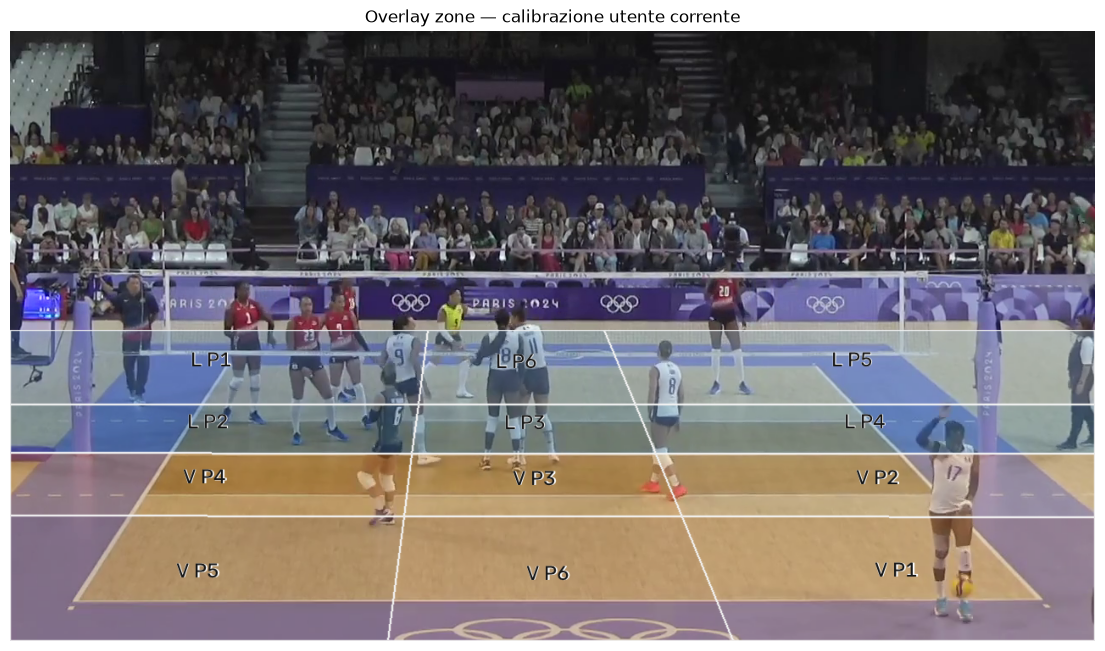

In [14]:
def clip_polygon_to_halfplane(polygon, line_coefficients, epsilon=0.0):
    """Clip a finite image polygon to a*x+b*y+c >= epsilon."""
    polygon = np.asarray(polygon, dtype=np.float64).reshape(-1, 2)
    if len(polygon) == 0:
        return polygon
    line = np.asarray(line_coefficients, dtype=np.float64)
    if line.shape != (3,) or not np.isfinite(line).all():
        raise ValueError("Clipping non valido: coefficienti di retta non finiti.")
    a, b, c = line
    output = []
    previous = polygon[-1]
    previous_value = a * previous[0] + b * previous[1] + c - epsilon
    previous_inside = previous_value >= 0
    for current in polygon:
        current_value = a * current[0] + b * current[1] + c - epsilon
        current_inside = current_value >= 0
        if current_inside != previous_inside:
            denominator = previous_value - current_value
            if abs(denominator) > 1e-15:
                t = previous_value / denominator
                output.append(previous + t * (current - previous))
        if current_inside:
            output.append(current)
        previous, previous_value, previous_inside = current, current_value, current_inside
    if not output:
        return np.empty((0, 2), dtype=np.float64)
    return np.asarray(output, dtype=np.float64)

def validate_opponent_extension_m(value):
    if isinstance(value, (bool, np.bool_)):
        raise ValueError("L'estensione avversaria deve essere un numero finito non negativo in metri.")
    try:
        value = float(value)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError("L'estensione avversaria deve essere un numero finito non negativo in metri.") from exc
    if not np.isfinite(value) or value < 0:
        raise ValueError("L'estensione avversaria deve essere un numero finito non negativo in metri.")
    return value

OPPONENT_BACKCOURT_EXTENSION_M = validate_opponent_extension_m(OPPONENT_BACKCOURT_EXTENSION_M)

def zone_image_polygon(row, col, width, height, image_to_world, denominator_sign=1.0, opponent_backcourt_extension_m=0.0):
    """Project one metric cell to image and clip it to a bounded frame rectangle."""
    opponent_backcourt_extension_m = validate_opponent_extension_m(opponent_backcourt_extension_m)
    x0, x1 = X_EDGES_M[col], X_EDGES_M[col + 1]
    y0, y1 = Y_EDGES_M[row], Y_EDGES_M[row + 1]
    if row == 0:
        y0 = -opponent_backcourt_extension_m
    g = np.asarray(image_to_world, dtype=np.float64)
    frame = np.array([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]], dtype=np.float64)
    polygon = clip_polygon_to_halfplane(frame, denominator_sign * g[2], epsilon=1e-4)
    constraints = []
    if col > 0:
        constraints.append(denominator_sign * (g[0] - x0 * g[2]))
    if col < 2:
        constraints.append(denominator_sign * (x1 * g[2] - g[0]))
    if row == 0:
        constraints.append(denominator_sign * (g[1] - y0 * g[2]))
    elif row > 0:
        constraints.append(denominator_sign * (g[1] - y0 * g[2]))
    if row < 3:
        constraints.append(denominator_sign * (y1 * g[2] - g[1]))
    for line in constraints:
        polygon = clip_polygon_to_halfplane(polygon, line)
        if len(polygon) < 3:
            return np.empty((0, 2), dtype=np.float64)
    return np.clip(polygon, [0, 0], [width - 1, height - 1])

def build_zone_id_mask(width, height, image_to_world, denominator_sign=1.0, background_polygons=None, opponent_backcourt_extension_m=0.0):
    """Return uint8 ID image: 0 background, 1..12 zones, clipped to frame."""
    opponent_backcourt_extension_m = validate_opponent_extension_m(opponent_backcourt_extension_m)
    ids = np.zeros((height, width), dtype=np.uint8)
    polygons = {}
    zone_id = 1
    for row in range(4):
        for col in range(3):
            polygon = zone_image_polygon(row, col, width, height, image_to_world, denominator_sign, opponent_backcourt_extension_m)
            polygons[zone_id] = polygon
            if len(polygon) >= 3:
                vertices = np.rint(polygon).astype(np.int32)
                cv2.fillPoly(ids, [vertices], int(zone_id), lineType=cv2.LINE_8)
            zone_id += 1
    for points in background_polygons or []:
        polygon = np.asarray(points, dtype=np.float64)
        if polygon.ndim != 2 or polygon.shape[1] != 2 or polygon.shape[0] < 3 or not np.isfinite(polygon).all():
            raise ValueError("Ogni poligono di sfondo deve contenere almeno tre punti pixel finiti.")
        polygon = clip_polygon_to_halfplane(polygon, [1, 0, 0])
        polygon = clip_polygon_to_halfplane(polygon, [-1, 0, width - 1])
        polygon = clip_polygon_to_halfplane(polygon, [0, 1, 0])
        polygon = clip_polygon_to_halfplane(polygon, [0, -1, height - 1])
        if len(polygon) >= 3:
            bg_mask = np.zeros_like(ids)
            cv2.fillPoly(bg_mask, [np.rint(polygon).astype(np.int32)], 1, lineType=cv2.LINE_8)
            ids[bg_mask > 0] = 0
    return ids, polygons

def make_overlay(frame_rgb, zone_ids, alpha=0.32):
    out = frame_rgb.astype(np.float32).copy()
    font_scale = max(0.55, min(frame_rgb.shape[:2]) / 900)
    labels = []
    for row in range(4):
        for col in range(3):
            zone_id = 1 + row * 3 + col
            color_hex = ZONE_COLORS[row][col]
            color = np.array([int(color_hex[i:i+2], 16) for i in (1, 3, 5)], dtype=np.float32)
            region = zone_ids == zone_id
            if region.any():
                out[region] = (1 - alpha) * out[region] + alpha * color
                ys, xs = np.where(region)
                cx, cy = int(xs.mean()), int(ys.mean())
                labels.append((ZONE_LABELS[row][col], (cx - 30, cy)))
    rendered = np.clip(out, 0, 255).astype(np.uint8)
    for label, origin in labels:
        cv2.putText(rendered, label, origin, cv2.FONT_HERSHEY_SIMPLEX, font_scale, (255, 255, 255), 3, cv2.LINE_AA)
        cv2.putText(rendered, label, origin, cv2.FONT_HERSHEY_SIMPLEX, font_scale, (20, 20, 20), 1, cv2.LINE_AA)
    for zone_id in range(1, 13):
        region = (zone_ids == zone_id).astype(np.uint8) * 255
        contours, _ = cv2.findContours(region, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if contours:
            cv2.drawContours(rendered, contours, -1, (245, 245, 245), max(1, int(min(frame_rgb.shape[:2]) / 600)), cv2.LINE_AA)
    rendered[zone_ids == 0] = frame_rgb[zone_ids == 0]
    return rendered

ZONE_ID_MASK, ZONE_POLYGONS = build_zone_id_mask(
    FRAME_WIDTH, FRAME_HEIGHT, H_IMAGE_TO_WORLD, VALID_DENOM_SIGN, BACKGROUND_POLYGONS_PX,
    opponent_backcourt_extension_m=OPPONENT_BACKCOURT_EXTENSION_M,
)
OVERLAY_RGB = make_overlay(FRAME_RGB, ZONE_ID_MASK)
print("Pixeli sfondo (ID 0):", int(np.count_nonzero(ZONE_ID_MASK == 0)))
for zone_id in range(1, 13):
    print(f"ID {zone_id:2}: {ZONE_LABELS[(zone_id-1)//3][(zone_id-1)%3]:4} — {int(np.count_nonzero(ZONE_ID_MASK == zone_id)):,} pixel")
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 8))
plt.imshow(OVERLAY_RGB)
plt.title("Overlay zone — calibrazione utente corrente")
plt.axis("off")
plt.show()

## Salvataggio della calibrazione e delle maschere

Questa cella salva gli angoli, tutti i punti rete confermati, le antenne opzionali saltate, la diagnostica camera 3D (schema 3), l'omografia e le 12 zone. Il fit stima fx, fy, cx e cy con skew zero e distorsione trascurata; residui alti o parametri al limite lasciano la camera `not_available` senza invalidare l'omografia. I JSON schema 1 e 2 restano caricabili; NPZ e overlay mantengono il formato precedente. L'estensione avversaria utente e conservata.


In [15]:
if CONFIRMED_CORNERS is None:
    raise RuntimeError("Nessun angolo confermato: non salvo una calibrazione provvisoria.")
OUTPUT_DIR = WORKSPACE_DIR / "zone_campo_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIDEO_STEM = VIDEO_PATH.stem
CALIBRATION_JSON = OUTPUT_DIR / f"calibrazione_{VIDEO_STEM}.json"
MASKS_NPZ = OUTPUT_DIR / f"maschere_zone_{VIDEO_STEM}.npz"
OVERLAY_PNG = OUTPUT_DIR / f"overlay_zone_{VIDEO_STEM}_{FRAME_SECONDS:g}s.png"

zone_map = {str(i): ZONE_LABELS[(i - 1) // 3][(i - 1) % 3] for i in range(1, 13)}
calibration = {
    "schema_version": 3,
    "confirmed_by_user": True,
    "video": str(VIDEO_PATH),
    "frame_seconds": FRAME_SECONDS,
    "image_width_px": FRAME_WIDTH,
    "image_height_px": FRAME_HEIGHT,
    "corner_order": CORNER_NAMES,
    "corners_image_px": CONFIRMED_CORNERS.tolist(),
    "net": {
        "status": "selected" if CONFIRMED_NET_CORRESPONDENCES is not None else "not_available",
        "height_m": COURT_NET_HEIGHT_M,
        "bottom_height_m_nominal": NET_BOTTOM_HEIGHT_M,
        "band_height_m_nominal": NET_BAND_HEIGHT_M,
        "antenna_extension_above_top_m_nominal": ANTENNA_EXTENSION_M,
        "antenna_tip_height_m_nominal": ANTENNA_TIP_HEIGHT_M,
        "height_reference": "rete femminile 2.24m al centro; fascia nominale larga 1m; antenna 0.80m sopra il nastro",
        "world_endpoints_xyz_m": [[0.0, COURT_LENGTH_M / 2.0, COURT_NET_HEIGHT_M], [COURT_WIDTH_M, COURT_LENGTH_M / 2.0, COURT_NET_HEIGHT_M]],
        "image_endpoints_xy_px": None if CONFIRMED_NET_SEGMENT is None else CONFIRMED_NET_SEGMENT.tolist(),
        "endpoint_order": ["lato associato al corner x=0", "lato associato al corner x=9"],
        "correspondences": CONFIRMED_NET_CORRESPONDENCES,
        "skipped_optional_points": CONFIRMED_SKIPPED_OPTIONAL_POINTS,
        "assumption": "top/bottom tape visibili; estremi possono differire fino a circa 0.02m e sag non modellato",
    },
    "camera_3d": CAMERA_3D_CALIBRATION,
    "court_width_m": COURT_WIDTH_M,
    "court_length_m": COURT_LENGTH_M,
    "opponent_backcourt_extension_m": OPPONENT_BACKCOURT_EXTENSION_M,
    "x_edges_m": X_EDGES_M,
    "y_edges_m": Y_EDGES_M,
    "zone_id_map": {"0": "background", **zone_map},
    "zone_labels_by_image_row": ZONE_LABELS,
    "H_world_to_image": H_WORLD_TO_IMAGE.tolist(),
    "H_image_to_world": H_IMAGE_TO_WORLD.tolist(),
    "valid_projective_halfspace": "denominator >= 1e-4 after center normalization",
    "background_polygons_image_px": BACKGROUND_POLYGONS_PX,
    "peripheral_regions": "graphic projective extensions to image edges; not surveyed floor or physical ball positions",
    "reuse_limit": "same fixed camera, framing and zoom only",
}
CALIBRATION_JSON.write_text(json.dumps(calibration, ensure_ascii=False, indent=2), encoding="utf-8")
np.savez_compressed(MASKS_NPZ, zone_id=ZONE_ID_MASK, zone_id_map_json=json.dumps(calibration["zone_id_map"], ensure_ascii=False), opponent_backcourt_extension_m=OPPONENT_BACKCOURT_EXTENSION_M)
if not cv2.imwrite(str(OVERLAY_PNG), cv2.cvtColor(OVERLAY_RGB, cv2.COLOR_RGB2BGR)):
    raise OSError(f"Impossibile salvare l'anteprima overlay: {OVERLAY_PNG}")
print("Calibrazione:", CALIBRATION_JSON)
print("Maschera (0 sfondo, 1..12 zone):", MASKS_NPZ)
print("Overlay:", OVERLAY_PNG)

Calibrazione: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\zone_campo_output\calibrazione_Test_demo_ITA_DOM_Parigi2024_30fps.json
Maschera (0 sfondo, 1..12 zone): C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\zone_campo_output\maschere_zone_Test_demo_ITA_DOM_Parigi2024_30fps.npz
Overlay: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\zone_campo_output\overlay_zone_Test_demo_ITA_DOM_Parigi2024_30fps_800s.png


## Ricaricare una calibrazione salvata

La funzione di caricamento mantiene la compatibilita con JSON schema 1 e 2; schema 3 aggiunge le corrispondenze 3D ridondanti e gli intrinseci stimati. L'omografia del pavimento e `opponent_backcourt_extension_m` restano indipendenti dalla validita della camera. I file precedenti senza estensione usano 0.0 m. Il back-project richiede `camera_3d.status == "estimated"`; restituisce solo una stima approssimata, non la posizione a terra. Riutilizza la calibrazione solo con camera, risoluzione e zoom invariati.


In [16]:
def load_calibration(json_path, frame_width, frame_height):
    data = json.loads(Path(json_path).read_text(encoding="utf-8"))
    if not data.get("confirmed_by_user"):
        raise ValueError("Il file non è marcato come calibrazione confermata dall'utente.")
    data["opponent_backcourt_extension_m"] = validate_opponent_extension_m(data.get("opponent_backcourt_extension_m", 0.0))
    data.setdefault("schema_version", 1)
    data.setdefault("net", None)
    data.setdefault("camera_3d", None)
    if (data["image_width_px"], data["image_height_px"]) != (frame_width, frame_height):
        raise ValueError("Risoluzione del frame diversa da quella della calibrazione.")
    H = np.asarray(data["H_image_to_world"], dtype=np.float64)
    if H.shape != (3, 3) or not np.isfinite(H).all() or abs(np.linalg.det(H)) < 1e-12:
        raise ValueError("Omografia salvata non valida.")
    return data, H

print("Per riusare: data, H_image_to_world = load_calibration(percorso_json, FRAME_WIDTH, FRAME_HEIGHT)")
print("I JSON legacy restano validi per l'omografia; net/camera_3d sono None se assenti.")
print("Per il back-project, usa back_project_ball_from_apparent_diameter(..., data['camera_3d']).")
print("Ricostruisci la maschera passando data['opponent_backcourt_extension_m'] a build_zone_id_mask.")

Per riusare: data, H_image_to_world = load_calibration(percorso_json, FRAME_WIDTH, FRAME_HEIGHT)
I JSON legacy restano validi per l'omografia; net/camera_3d sono None se assenti.
Per il back-project, usa back_project_ball_from_apparent_diameter(..., data['camera_3d']).
Ricostruisci la maschera passando data['opponent_backcourt_extension_m'] a build_zone_id_mask.
